<a href="https://colab.research.google.com/github/emmushka2005/Data144_Final_Project/blob/main/04_Clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 04 – Clustering the review embeddings (k-means)

**Goal:** Group reviews with similar Word2Vec vectors and read examples to identify common themes. The sentiment analysis can then use the cluster labels to compare customer feedback across groups.

**Plan**
1. Load the review vectors (from notebook 03) and the review table (from notebook 02), and make the *row key* explicit
2. Prepare the vectors (drop empty vectors, L2-normalise)
3. Try several values of K with k-means: silhouette score + inertia (elbow)
4. Choose K and explain why
5. Describe each cluster: size, distinctive words, example reviews, average star rating -> give each a theme label
6. Visualise the clusters in 2D (PCA and UMAP)
7. Save `cluster_labels.csv` for the sentiment teammate
8. summary of how K was chosen and how the groups were interpreted

## 1. Load the review vectors and cleaned reviews
The next cell loads beauty_review_vectors.npy from notebook 03 and beauty_clean.pkl from notebook 02. Both files are loaded from the current working folder.

In [2]:
%pip install -q "pandas>=3,<4"

In [3]:
import pandas as pd
import numpy as np

# Load vectors and review information
review_matrix = np.load("beauty_review_vectors.npy")
df = pd.read_pickle("beauty_clean.pkl")

print("Vectors:", review_matrix.shape)
print("Reviews:", df.shape)

Vectors: (693547, 100)
Reviews: (693547, 10)


### The row key (how to match reviews to vectors and to the sentiment results)

* **Row `i` of `review_matrix` is the review in row `i` of `df`** (notebook 03 tokenised `df["clean_text"]` in order and averaged the Word2Vec vectors, so the order is the same). I call this `row_position` (0 ... 693,546).
* `df.index` is kept as `clean_index`. In notebook 02 the index is the row number of the de-duplicated review table; removing the 705 empty reviews left gaps in it, so it is **not** the same as `row_position`.
* If `beauty_raw_row.npy` is in the current folder there is also `raw_row`: the line number of the review in the original `All_Beauty.jsonl.gz` (= the index of `beauty_reviews` in notebooks 01 and 02). This file is optional and is not required in Colab; if it is missing, the CSV is still written, just without a `raw_row` column.

The saved CSV always includes `row_position`, `clean_index`, `cluster_id` and `theme_label` (plus `user_id` / `parent_asin` / `rating` when those columns are in the review table), so a teammate can join on `row_position` or `clean_index`.


In [4]:
assert len(df) == len(review_matrix), "vectors and reviews must have the same number of rows"

from pathlib import Path
df = df.drop(columns=[c for c in ["text", "categories", "product_title", "store"] if c in df.columns])  # free memory
df["clean_index"] = df.index          # index label in beauty_clean.pkl
df = df.reset_index(drop=True)
df["row_position"] = np.arange(len(df))   # row number in review_matrix
# Optional: line number in the raw All_Beauty.jsonl.gz (only if you uploaded beauty_raw_row.npy)
raw_path = Path("beauty_raw_row.npy")
if raw_path.is_file():
    df["raw_row"] = np.load(raw_path)
    print("Loaded raw_row from", raw_path)
else:
    print("beauty_raw_row.npy was not found in the current folder. The CSV will be saved without the raw_row column.")
print(df[["row_position", "clean_index"] + [c for c in ["raw_row"] if c in df.columns] + ["rating", "sentiment"]].head())
print(df[["row_position", "clean_index"]].tail(3))
print("\nRating distribution:\n", df["rating"].value_counts().sort_index().to_string())


beauty_raw_row.npy was not found in the current folder. The CSV will be saved without the raw_row column.
   row_position  clean_index  rating sentiment
0             0            0       5  Positive
1             1            1       4  Positive
2             2            2       5  Positive
3             3            3       1  Negative
4             4            4       5  Positive
        row_position  clean_index
693544        693544       694249
693545        693545       694250
693546        693546       694251

Rating distribution:
 rating
1    100756
2     42577
3     55696
4     78546
5    415972


## 2. Prepare the vectors

Each review vector is the **average of its Word2Vec word vectors** (notebook 03). Two things to handle before k-means:

1. **Reviews with no usable words.** If none of a review's words are in the Word2Vec vocabulary, notebook 03 gave it an all-zero vector. A zero vector says nothing about the review, so these are left out of the clustering and get `cluster_id = -1` in the CSV.
2. **L2-normalising.** I scaled each nonzero review vector to length 1 before running k-means. After this step, the distance between two review vectors depends on their directions. This prevents differences in vector length from dominating the comparison.

In [5]:
zero_mask = ~review_matrix.any(axis=1)
print("Reviews with an all-zero vector (no known words):", int(zero_mask.sum()))

valid_idx = np.where(~zero_mask)[0]                     # row positions that will be clustered
X = review_matrix[valid_idx].astype(np.float32)
norms = np.linalg.norm(X, axis=1, keepdims=True)
X = X / norms                                            # L2-normalise: every row has length 1
print("Clustering matrix:", X.shape, "| row lengths after scaling (min, max):", float(np.linalg.norm(X, axis=1).min()), float(np.linalg.norm(X, axis=1).max()))
print("Raw vector length quartiles (before scaling):", np.percentile(norms, [25, 50, 75]).round(3))

Reviews with an all-zero vector (no known words): 1298
Clustering matrix: (692249, 100) | row lengths after scaling (min, max): 0.9999997615814209 1.000000238418579
Raw vector length quartiles (before scaling): [1.422 1.503 1.677]


## 3. Try different values of K

For every K from 2 to 10 I run k-means (`n_init=10`, `random_state=42`, so the result can be repeated) and record:

* **Silhouette score** (-1 to 1; higher = reviews sit closer to their own cluster than to the nearest other cluster). It needs all pairwise distances, so it is computed on a random sample of 20,000 reviews (`sample_size=20000`).
* **Inertia** (sum of squared distances to the cluster centres; In our results, inertia decreased as K increased. We looked for the point where adding another cluster gave a smaller improvement.)

To keep this fast on a laptop, the sweep fits k-means on a fixed random sample of **100,000 reviews** (out of 693k). The final model for the chosen K is then fitted on all 692,249 reviews with nonzero vectors.

In [6]:
import time
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

rng = np.random.RandomState(42)
sweep_pos = rng.choice(len(X), size=100_000, replace=False)
X_sweep = X[sweep_pos]

K_RANGE = range(2, 11)
rows = []
for k in K_RANGE:
    t0 = time.time()
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_sweep)
    sil = silhouette_score(X_sweep, km.labels_, sample_size=20_000, random_state=42)
    smallest = np.bincount(km.labels_).min() / len(X_sweep)
    rows.append({"K": k, "silhouette": sil, "inertia": km.inertia_, "smallest_cluster_share": smallest})
    print(f"K={k:2d}  silhouette={sil:.4f}  inertia={km.inertia_:,.0f}  smallest cluster={smallest:.1%}  ({time.time()-t0:.0f}s)")

sweep = pd.DataFrame(rows)
sweep["inertia_drop_%"] = (-sweep["inertia"].pct_change() * 100).round(2)
sweep.round(4)

K= 2  silhouette=0.2206  inertia=24,166  smallest cluster=21.3%  (31s)
K= 3  silhouette=0.1934  inertia=22,543  smallest cluster=1.7%  (31s)
K= 4  silhouette=0.0405  inertia=21,842  smallest cluster=1.7%  (26s)
K= 5  silhouette=0.0428  inertia=21,274  smallest cluster=1.7%  (24s)
K= 6  silhouette=0.0511  inertia=20,800  smallest cluster=1.7%  (30s)
K= 7  silhouette=0.0371  inertia=20,433  smallest cluster=1.7%  (32s)
K= 8  silhouette=0.0401  inertia=20,104  smallest cluster=1.7%  (30s)
K= 9  silhouette=0.0426  inertia=19,786  smallest cluster=1.7%  (29s)
K=10  silhouette=0.0335  inertia=19,499  smallest cluster=1.7%  (32s)


,K,silhouette,inertia,smallest_cluster_share,inertia_drop_%
0,2,0.2206,24166.3887,0.2132,NaN
1,3,0.1934,22543.0449,0.0170,6.72
2,4,0.0405,21841.6621,0.0170,3.11
3,5,0.0428,21274.0195,0.0170,2.60
4,6,0.0511,20800.2070,0.0170,2.23
5,7,0.0371,20433.0723,0.0170,1.77
6,8,0.0401,20104.2637,0.0170,1.61
7,9,0.0426,19785.7520,0.0170,1.58
8,10,0.0335,19499.2012,0.0170,1.45


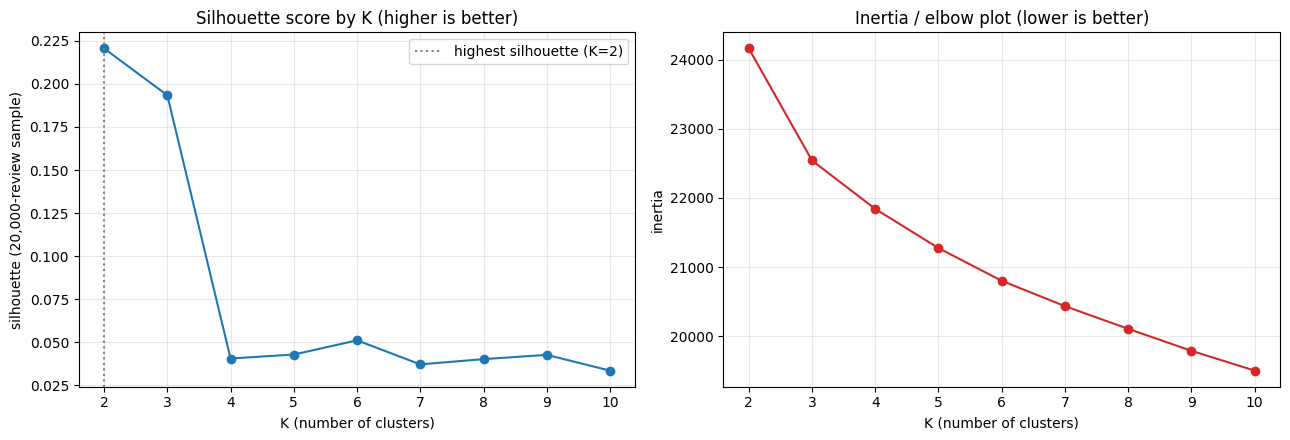

In [7]:
import matplotlib.pyplot as plt

FIGURES_DIR = Path("figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(sweep["K"], sweep["silhouette"], "o-", color="tab:blue")
best_k = int(sweep.loc[sweep["silhouette"].idxmax(), "K"])
ax[0].axvline(best_k, color="grey", ls=":", label=f"highest silhouette (K={best_k})")
ax[0].set_title("Silhouette score by K (higher is better)"); ax[0].set_xlabel("K (number of clusters)"); ax[0].set_ylabel("silhouette (20,000-review sample)"); ax[0].legend()
ax[1].plot(sweep["K"], sweep["inertia"], "o-", color="tab:red")
ax[1].set_title("Inertia / elbow plot (lower is better)"); ax[1].set_xlabel("K (number of clusters)"); ax[1].set_ylabel("inertia")
for a in ax: a.set_xticks(list(K_RANGE)); a.grid(alpha=.3)
plt.tight_layout(); fig.savefig(FIGURES_DIR / "silhouette_and_elbow.png", dpi=150, bbox_inches="tight"); plt.show()



## 4. Choosing K

I tested K values from 2 to 10. K = 2 had the highest silhouette score (0.2206). I chose K = 8 because the top words and example reviews helped me identify themes such as product complaints, skincare and scent, and beauty accessories.

I fitted the final K = 8 model on all 692,249 reviews with usable vectors. Its silhouette score was 0.0370 on a sample of 30,000 reviews, which suggests that the groups overlap. The complaints group had the lowest average rating (2.89 stars), and 45.41% of its reviews gave one or two stars.


In [8]:
K = 8   # chosen number of clusters (see the reasoning above)

km = KMeans(n_clusters=K, n_init=10, random_state=42).fit(X)       # final model on ALL clustered reviews
raw_labels = km.labels_

# renumber clusters 0..K-1 from biggest to smallest so the ids are easy to read
order = np.argsort(-np.bincount(raw_labels))
remap = {old: new for new, old in enumerate(order)}
labels = np.array([remap[l] for l in raw_labels])
centers = km.cluster_centers_[order]

sil_final = silhouette_score(X, labels, sample_size=30_000, random_state=42)
print(f"Final k-means: K={K}, inertia={km.inertia_:,.0f}, silhouette (30,000-review sample) = {sil_final:.4f}")

# put the labels back on the full table (-1 = review had no usable vector)
df["cluster_id"] = -1
df.loc[valid_idx, "cluster_id"] = labels

Final k-means: K=8, inertia=139,059, silhouette (30,000-review sample) = 0.0370


## 5. What is in each cluster?

For every cluster: how big it is, its **mean star rating**, the most distinctive words (TF-IDF: words used much more in this cluster than in the corpus overall; computed on a 150,000-review sample with English stop-words removed) and example reviews. For each cluster, I show the five reviews closest to its center and five randomly selected reviews from that cluster with at least 60 characters.

In [9]:
from sklearn.feature_extraction.text import TfidfVectorizer

summary = (df[df.cluster_id >= 0].groupby("cluster_id")
           .agg(size=("rating", "size"), mean_rating=("rating", "mean"),
                pct_1_2_star=("rating", lambda r: (r <= 2).mean() * 100),
                pct_4_5_star=("rating", lambda r: (r >= 4).mean() * 100),
                median_words=("clean_text", lambda t: t.str.split().str.len().median())))
summary["share_%"] = summary["size"] / summary["size"].sum() * 100
print("Overall mean rating:", round(df["rating"].mean(), 3))
summary.round(2)

Overall mean rating: 3.961


,size,mean_rating,pct_1_2_star,pct_4_5_star,median_words,share_%
cluster_id,,,,,,
0,203414,3.90,22.06,69.68,34.0,29.38
1,148287,2.89,45.41,40.19,23.0,21.42
2,100635,4.52,7.76,87.64,20.0,14.54
3,90506,4.20,14.24,77.51,22.0,13.07
4,63111,4.33,11.79,81.91,6.0,9.12
5,37808,4.91,0.69,98.68,5.0,5.46
6,36869,4.85,0.90,97.64,2.0,5.33
7,11619,4.07,19.55,74.86,7.0,1.68


In [10]:
tfidf_pos = np.random.RandomState(1).choice(valid_idx, size=150_000, replace=False)
tf = TfidfVectorizer(stop_words="english", ngram_range=(1, 2), min_df=30, max_df=0.5, sublinear_tf=True, max_features=30_000)
T = tf.fit_transform(df.loc[tfidf_pos, "clean_text"])
terms = np.array(tf.get_feature_names_out())
lab_tf = df.loc[tfidf_pos, "cluster_id"].values
overall = np.asarray(T.mean(axis=0)).ravel()

top_terms = {}
for c in range(K):
    m = np.asarray(T[lab_tf == c].mean(axis=0)).ravel() - overall      # cluster mean TF-IDF minus corpus mean
    top_terms[c] = list(terms[np.argsort(-m)[:15]])
    print(f"Cluster {c}: ", ", ".join(top_terms[c]), "\n")

Cluster 0:  used, product, ve, br, buy, using, time, bought, just, years, got, like, received, order, ordered 

Cluster 1:  doesn, does, work, don, money, waste, didn, waste money, hard, hair, did, like, stay, hold, easy 

Cluster 2:  skin, smells, scent, face, smell, dry, makes, feels, smooth, leaves, soft, oil, works, feel, clean 

Cluster 3:  lashes, colors, cute, look, perfect, brushes, headbands, fit, clips, ones, work, wear, super, nails, size 

Cluster 4:  nice, good, quality, beautiful, cute, described, expected, ok, pretty, good quality, exactly, soft, super, easy, color 

Cluster 5:  love, loved, loves, daughter, gift, love product, love love, wife, daughter loves, absolutely, granddaughter, favorite, bought, absolutely love, perfect 

Cluster 6:  great, good, great product, product, works, excellent, works great, perfect, good product, awesome, price, great price, value, quality, thank 

Cluster 7:  muy, el, excelente, es, la, lo, que, producto, para, se, bueno, en, bien, bu

In [11]:
import textwrap
def show(rows, n=260):
    for _, r in rows.iterrows():
        print(f"   [{int(r.rating)}*] " + textwrap.shorten(r.clean_text, n))

for c in range(K):
    members = valid_idx[labels == c]
    d = np.linalg.norm(X[labels == c] - centers[c], axis=1)
    nearest = members[np.argsort(d)[:5]]
    pool = df.loc[members]; pool = pool[pool["clean_text"].str.len() >= 60]
    rand = pool.sample(5, random_state=7)
    print(f"=== Cluster {c} | n={len(members):,} | mean rating {df.loc[members,'rating'].mean():.2f} ===")
    print("  closest to the centre:"); show(df.loc[nearest])
    print("  random members:"); show(rand); print()

=== Cluster 0 | n=203,414 | mean rating 3.90 ===
  closest to the centre:
   [5*] This has got to be the BEST hair mask I have ever used hands down! I bought a sample packet of this at my local Sally’s Beauty supply shop. It was one of those “you have to spend $3 more to use your coupon” purchases. Thankfully I can gladly say that I [...]
   [5*] After using the braun silk epil for many years ( I was in my teenage years when I first started) I must say they came a long way . Also My older model rotates much faster, this one gets the job done. The light on it is pretty bright and I am sure some [...]
   [5*] Before I came across this type of brush, I was using those typical plastic brushes that you would buy at the store--that was at least 3 years ago, if not, more than that. Eventually, I got tired of plastic brushes because of the way it pulls, the static [...]
   [5*] It took over a month for this to reach me, which was frustrating. The product is very nice. I like the packaging. The

### Theme labels

The labels below were written **after reading the top words and example reviews above** (not guessed in advance):

In [12]:
THEME = {
    0: "Longer reviews about personal experiences",
    1: "Product problems and complaints about value",
    2: "Skincare, scent, and how products feel",
    3: "Beauty accessories, appearance, and fit",
    4: "Short comments on quality, appearance, and expectations",
    5: "Love-it reviews, including gifts and family purchases",
    6: "Short general praise, such as great product or works great",
    7: "Spanish-language reviews",
}
df["theme_label"] = df["cluster_id"].map(THEME).fillna("no usable embedding (no known words)")

summary["theme"] = pd.Series(THEME)
summary["top_words"] = pd.Series({c: ", ".join(top_terms[c][:8]) for c in top_terms})
summary[["theme", "size", "share_%", "mean_rating", "pct_1_2_star", "top_words"]].round(2)

,theme,size,share_%,mean_rating,pct_1_2_star,top_words
cluster_id,,,,,,
0,Longer reviews about personal experiences,203414,29.38,3.90,22.06,"used, product, ve, br, buy, using, time, bought"
1,Product problems and complaints about value,148287,21.42,2.89,45.41,"doesn, does, work, don, money, waste, didn, wa..."
2,"Skincare, scent, and how products feel",100635,14.54,4.52,7.76,"skin, smells, scent, face, smell, dry, makes, ..."
3,"Beauty accessories, appearance, and fit",90506,13.07,4.20,14.24,"lashes, colors, cute, look, perfect, brushes, ..."
4,"Short comments on quality, appearance, and exp...",63111,9.12,4.33,11.79,"nice, good, quality, beautiful, cute, describe..."
5,"Love-it reviews, including gifts and family pu...",37808,5.46,4.91,0.69,"love, loved, loves, daughter, gift, love produ..."
6,"Short general praise, such as great product or...",36869,5.33,4.85,0.90,"great, good, great product, product, works, ex..."
7,Spanish-language reviews,11619,1.68,4.07,19.55,"muy, el, excelente, es, la, lo, que, producto"


## 6. Visualising the clusters in 2D

The vectors have 100 dimensions, so they are squashed to 2 for plotting. **PCA** (linear; keeps the biggest directions of variation) is fitted on a 40,000-review sample. **UMAP** (non-linear; keeps neighbourhoods) is run on a 30,000-review sample because it is slow on all 693k. The colours are the k-means clusters and the legend gives the theme labels. Only the picture is simplified; the clusters themselves were found in the full 100 dimensions.

PCA explained variance (2 components): [0.116 0.072] total 0.188


/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


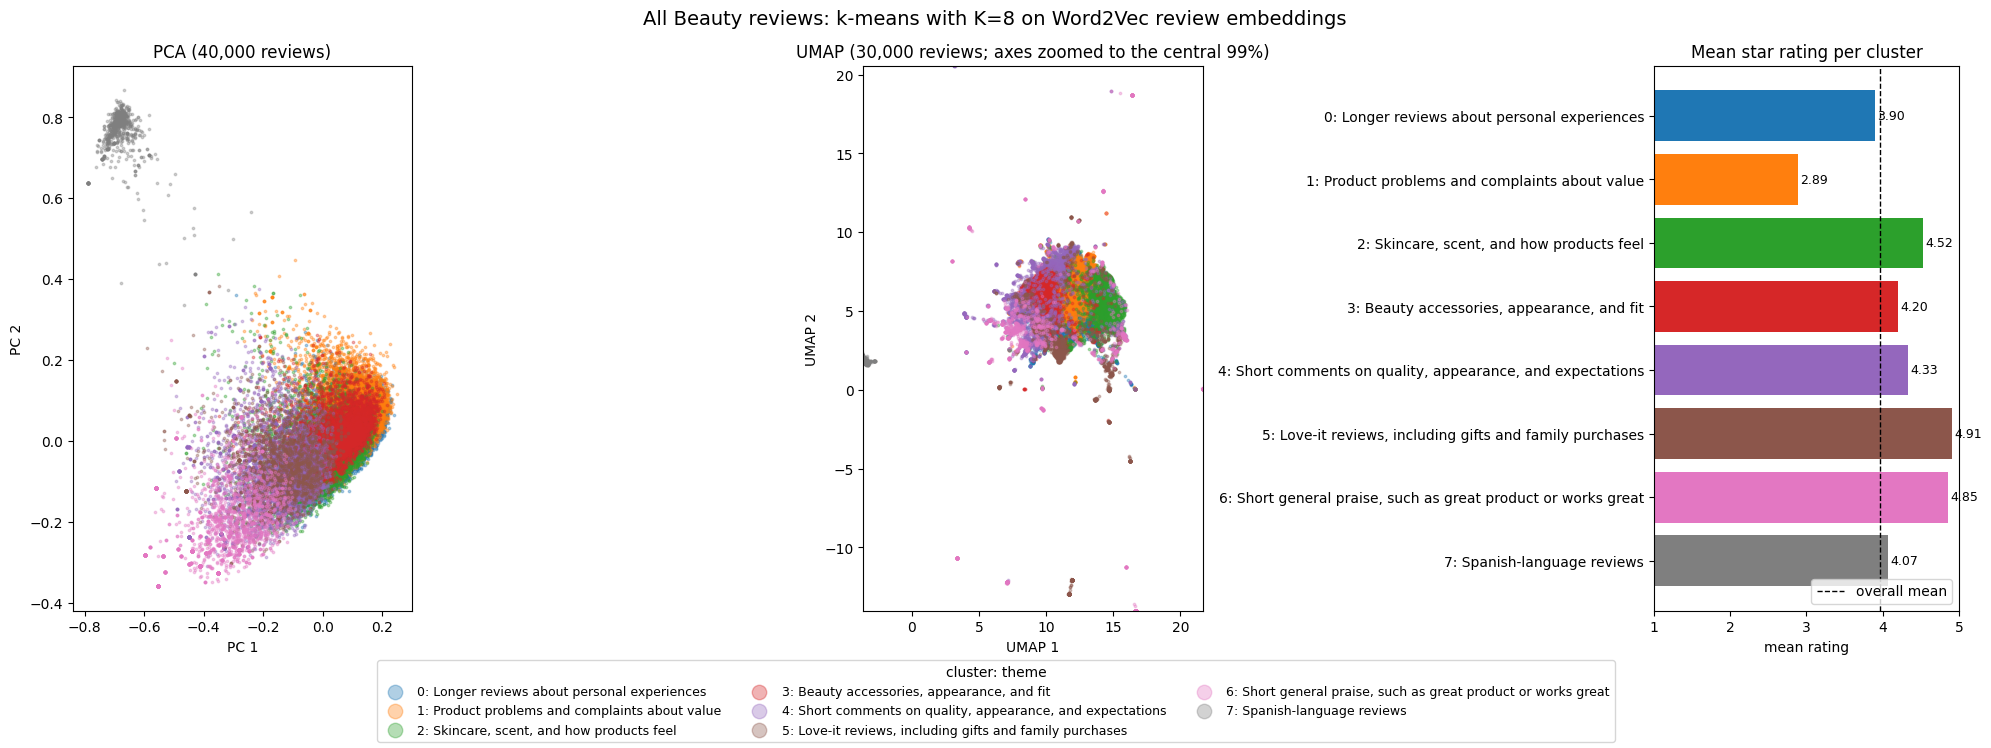

In [13]:
from sklearn.decomposition import PCA
import umap

pal = plt.get_cmap("tab10")
legend_names = {c: f"{c}: {THEME[c]}" for c in range(K)}

viz_pos = np.random.RandomState(3).choice(len(X), size=40_000, replace=False)
pca = PCA(n_components=2, random_state=42).fit(X[viz_pos])
P = pca.transform(X[viz_pos]); lab_p = labels[viz_pos]
print("PCA explained variance (2 components):", pca.explained_variance_ratio_.round(3), "total", pca.explained_variance_ratio_.sum().round(3))

um_sub = viz_pos[:30_000]
reducer = umap.UMAP(n_neighbors=30, min_dist=0.1, n_components=2, random_state=42)
U = reducer.fit_transform(X[um_sub]); lab_u = labels[um_sub]

def scatter(ax, Z, lab, title, xl, yl):
    for c in range(K):
        ax.scatter(Z[lab == c, 0], Z[lab == c, 1], s=3, alpha=.35, color=pal(c), label=legend_names[c], rasterized=True)
    ax.set_title(title); ax.set_xlabel(xl); ax.set_ylabel(yl)

def zoom(ax, Z):   # ignore the few far-away outliers when setting the axis limits
    ax.set_xlim(*np.percentile(Z[:, 0], [0.5, 99.5])); ax.set_ylim(*np.percentile(Z[:, 1], [0.5, 99.5]))

for name, Z, lab, t, xl, yl in [("cluster_pca", P, lab_p, "PCA of review embeddings (40,000-review sample)", "PC 1", "PC 2"),
                                ("cluster_umap", U, lab_u, "UMAP of review embeddings (30,000-review sample)", "UMAP 1", "UMAP 2")]:
    f, a = plt.subplots(figsize=(9, 7)); scatter(a, Z, lab, t, xl, yl); zoom(a, Z) if "umap" in name else None
    a.legend(markerscale=6, fontsize=8, loc="best", title="cluster: theme"); plt.tight_layout(); plt.savefig(FIGURES_DIR / f"{name}.png", dpi=150); plt.close(f)

# main results figure: PCA + UMAP + mean rating per cluster
fig, ax = plt.subplots(1, 3, figsize=(20, 7.5), gridspec_kw={"width_ratios": [1, 1, 0.9]})
scatter(ax[0], P, lab_p, "PCA (40,000 reviews)", "PC 1", "PC 2")
scatter(ax[1], U, lab_u, "UMAP (30,000 reviews; axes zoomed to the central 99%)", "UMAP 1", "UMAP 2"); zoom(ax[1], U)
h, l = ax[1].get_legend_handles_labels()
fig.legend(h, l, markerscale=6, fontsize=9, loc="lower center", ncol=3, title="cluster: theme")
ax[2].barh([legend_names[c] for c in range(K)][::-1], summary["mean_rating"].values[::-1], color=[pal(c) for c in range(K)][::-1])
ax[2].axvline(df["rating"].mean(), color="k", ls="--", lw=1, label="overall mean"); ax[2].set_xlim(1, 5)
ax[2].set_title("Mean star rating per cluster"); ax[2].set_xlabel("mean rating"); ax[2].legend(loc="lower right")
for i, v in enumerate(summary["mean_rating"].values[::-1]): ax[2].text(v + 0.03, i, f"{v:.2f}", va="center", fontsize=9)
fig.suptitle(f"All Beauty reviews: k-means with K={K} on Word2Vec review embeddings", fontsize=14)
plt.tight_layout(rect=(0, 0.1, 1, 1)); fig.savefig(FIGURES_DIR / "cluster_summary.png", dpi=150, bbox_inches="tight"); plt.show()


## 7. Save the cluster labels for the sentiment analysis

In [14]:
out_cols = ["row_position", "clean_index"] + [c for c in ["raw_row", "user_id", "parent_asin"] if c in df.columns] + ["rating", "cluster_id", "theme_label"]
out = df[out_cols]
labels_path = Path("cluster_labels.csv")
out.to_csv(labels_path, index=False)
print(f"Saved {labels_path}:", out.shape)
print(out["cluster_id"].value_counts().sort_index().to_string())
out.head()


Saved cluster_labels.csv: (693547, 7)
cluster_id
-1      1298
 0    203414
 1    148287
 2    100635
 3     90506
 4     63111
 5     37808
 6     36869
 7     11619


,row_position,clean_index,user_id,parent_asin,rating,cluster_id,theme_label
0,0,0,AGKHLEW2SOWHNMFQIJGBECAF7INQ,B00YQ6X8EO,5,0,Longer reviews about personal experiences
1,1,1,AGKHLEW2SOWHNMFQIJGBECAF7INQ,B081TJ8YS3,4,0,Longer reviews about personal experiences
2,2,2,AE74DYR3QUGVPZJ3P7RFWBGIX7XQ,B097R46CSY,5,6,"Short general praise, such as great product or..."
3,3,3,AFQLNQNQYFWQZPJQZS6V3NZU4QBQ,B09JS339BZ,1,4,"Short comments on quality, appearance, and exp..."
4,4,4,AFQLNQNQYFWQZPJQZS6V3NZU4QBQ,B08BZ63GMJ,5,5,"Love-it reviews, including gifts and family pu..."


In [15]:
# sanity check: reload the file and make sure the row keys line up with the vectors / review table
chk = pd.read_csv(labels_path)
assert len(chk) == len(review_matrix) and (chk["row_position"].values == np.arange(len(chk))).all()
assert (chk["cluster_id"].values == df["cluster_id"].values).all()
assert (chk.loc[~zero_mask, "cluster_id"] >= 0).all() and (chk.loc[zero_mask, "cluster_id"] == -1).all()
print("OK: one row per review, row_position matches the row of review_matrix, cluster ids match")


OK: one row per review, row_position matches the row of review_matrix, cluster ids match


### 8. How we chose K and interpreted the groups

1. **Preparing the reviews.** Notebook 03 represented each review with 100 numbers by averaging its Word2Vec word vectors. Of the 693,547 reviews, 1,298 had no words in the model’s vocabulary. We assigned them `cluster_id = -1`. We scaled each of the remaining 692,249 vectors to length 1 before clustering.

2. **Testing different values of K.** We tested K = 2 through K = 10 on the same random sample of 100,000 reviews. For each K, we recorded inertia and calculated a silhouette score on 20,000 reviews. A higher silhouette score means reviews generally fit their own group better.

3. **Choosing K = 8.** K = 2 had the highest silhouette score (0.2206). We chose K = 8 because the top words and example reviews helped us identify themes such as product complaints, skincare and scent, and beauty accessories. We fitted the final model on all 692,249 usable vectors. Its silhouette score was 0.0370 on a sample of 30,000 reviews, which suggests the groups overlap.

4. **Naming the groups.** We used TF-IDF to find words and phrases that stood out in each cluster. We read the five reviews closest to each cluster center and five reviews randomly selected from members with at least 60 characters. We also compared the average star ratings across clusters.

#### **The eight clusters**

The percentages below are based on the 692,249 reviews included in clustering.

#### **What this means for the project**

**Cluster 1 is the best starting point for investigating complaints.** It had the lowest average rating, and 45.41% of its reviews gave one or two stars. However, 40.19% gave four or five stars. Comparing sentiment within this cluster can help us understand why customers discussing similar product issues gave different ratings.

The clusters also reflect how people write. Cluster 6 contains very short praise, while cluster 7 groups reviews by language. Averaging word vectors loses word order, which can make phrases such as “not good” harder to interpret. The low silhouette score is another reason to treat the themes as a guide when exploring individual reviews.

**Saved files.** `cluster_labels.csv` contains one row for each of the 693,547 reviews, including the 1,298 assigned `-1`. Use `clean_index` to match a review to its original index in `beauty_clean.pkl`, or use `row_position` to match it to its row in the vector matrix. The plots are saved in the `figures` folder.

In [16]:
cluster_table = summary[
    ["theme", "size", "share_%", "mean_rating", "top_words"]
].rename(columns={
    "theme": "Theme",
    "size": "Reviews",
    "share_%": "Share",
    "mean_rating": "Mean stars",
    "top_words": "Distinctive words"
})

cluster_table.index.name = "Cluster ID"

cluster_table.style.format({
    "Reviews": "{:,}",
    "Share": "{:.2f}%",
    "Mean stars": "{:.2f}"
})

,Theme,Reviews,Share,Mean stars,Distinctive words
Cluster ID,,,,,
0,Longer reviews about personal experiences,"203,414",29.38%,3.90,"used, product, ve, br, buy, using, time, bought"
1,Product problems and complaints about value,"148,287",21.42%,2.89,"doesn, does, work, don, money, waste, didn, waste money"
2,"Skincare, scent, and how products feel","100,635",14.54%,4.52,"skin, smells, scent, face, smell, dry, makes, feels"
3,"Beauty accessories, appearance, and fit","90,506",13.07%,4.20,"lashes, colors, cute, look, perfect, brushes, headbands, fit"
4,"Short comments on quality, appearance, and expectations","63,111",9.12%,4.33,"nice, good, quality, beautiful, cute, described, expected, ok"
5,"Love-it reviews, including gifts and family purchases","37,808",5.46%,4.91,"love, loved, loves, daughter, gift, love product, love love, wife"
6,"Short general praise, such as great product or works great","36,869",5.33%,4.85,"great, good, great product, product, works, excellent, works great, perfect"
7,Spanish-language reviews,"11,619",1.68%,4.07,"muy, el, excelente, es, la, lo, que, producto"
